In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
iris=load_iris()

df=pd.DataFrame(iris.data,columns=iris.feature_names)
df['Species']=iris.target

print(df.head())
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Distribution:")
print(df['Species'].value_counts())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int6

In [4]:
x=df.drop('Species',axis=1)
y=df['Species']

print("Features Shape:",x.shape)
print("Target Shape:",y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


In [5]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:",x_train.shape)
print("Testing Data:",x_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [6]:
scaler=StandardScaler()

x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [8]:
linear_svm=SVC(
    kernel='linear',
    C=1.0
)

linear_svm.fit(x_train_scaled,y_train)

print("Linear SVM Model Trained Successfully")

Linear SVM Model Trained Successfully


In [11]:
y_pred_linear = linear_svm.predict(x_test_scaled)
print("Linear SVM Predictions:")
print(y_pred_linear)

Linear SVM Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [14]:
print("LINEAR SVM EVALUATION")
print("Accuracy:",accuracy_score(y_test,y_pred_linear))

print("Precision:",precision_score(y_test, y_pred_linear, average='weighted'))

print("Recall:",recall_score(y_test, y_pred_linear, average='weighted'))

print("F1 Score:",
      f1_score(y_test, y_pred_linear, average='weighted'))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_linear,
    target_names=iris.target_names
))

LINEAR SVM EVALUATION
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [9]:
rbf_svm=SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

rbf_svm.fit(x_train_scaled,y_train)

print("RBF SVM Model Trained Successfully")

RBF SVM Model Trained Successfully


In [12]:
y_pred_rbf = rbf_svm.predict(x_test_scaled)

print("\nRBF SVM Predictions:")
print(y_pred_rbf)


RBF SVM Predictions:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [15]:
print("RBF SVM EVALUATION")
print("Accuracy:",accuracy_score(y_test, y_pred_rbf))

print("Precision:",precision_score(y_test, y_pred_rbf, average='weighted'))

print("Recall:",recall_score(y_test, y_pred_rbf, average='weighted'))

print("F1 Score:",f1_score(y_test, y_pred_rbf, average='weighted'))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=iris.target_names
))

RBF SVM EVALUATION
Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9665831244778613

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [16]:
comparison={
    'Model': ['Linear SVM', 'RBF SVM'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_linear),
        accuracy_score(y_test, y_pred_rbf)
    ],

    'Precision': [
        precision_score(y_test, y_pred_linear, average='weighted'),
        precision_score(y_test, y_pred_rbf, average='weighted')
    ],

    'Recall': [
        recall_score(y_test, y_pred_linear, average='weighted'),
        recall_score(y_test, y_pred_rbf, average='weighted')
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_linear, average='weighted'),
        f1_score(y_test, y_pred_rbf, average='weighted')
    ]
}

comparison_df = pd.DataFrame(comparison)

print(comparison_df)

        Model  Accuracy  Precision    Recall  F1 Score
0  Linear SVM  1.000000   1.000000  1.000000  1.000000
1     RBF SVM  0.966667   0.969697  0.966667  0.966583


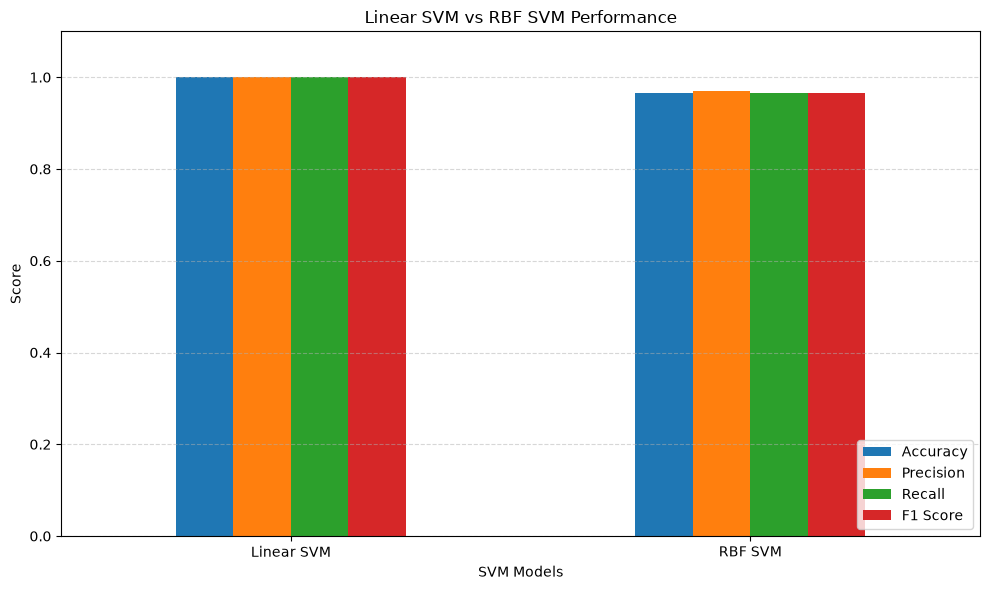

In [17]:
comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1.1)
)

plt.title("Linear SVM vs RBF SVM Performance")
plt.ylabel("Score")
plt.xlabel("SVM Models")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

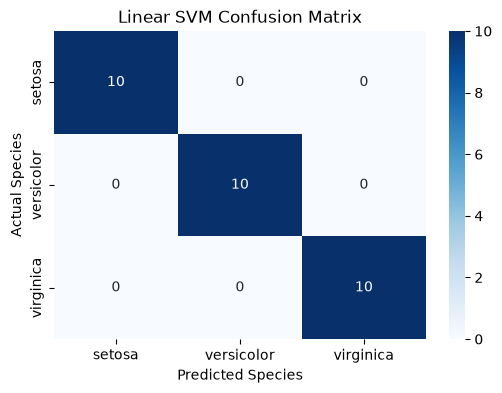

In [18]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_linear,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

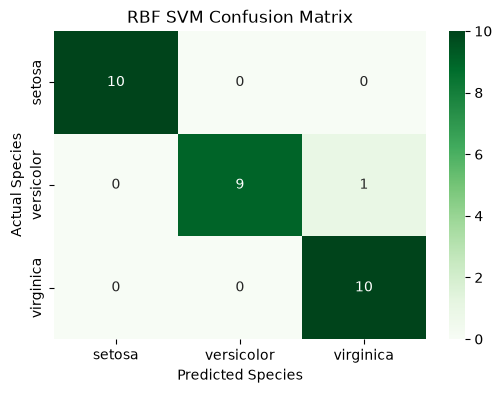

In [19]:
cm_rbf=confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("RBF SVM Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [20]:
best_model=comparison_df.loc[
    comparison_df['Accuracy'].idxmax()
]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model        Linear SVM
Accuracy            1.0
Precision           1.0
Recall              1.0
F1 Score            1.0
Name: 0, dtype: object


In [21]:
new_flower=[[5.1, 3.5, 1.4, 0.2]]
new_flower_scaled=scaler.transform(new_flower)

linear_prediction=linear_svm.predict(new_flower_scaled)

rbf_prediction=rbf_svm.predict(new_flower_scaled)

print("Linear SVM Prediction:",iris.target_names[linear_prediction[0]])

print("RBF SVM Prediction:",iris.target_names[rbf_prediction[0]])

Linear SVM Prediction: setosa
RBF SVM Prediction: setosa


C:\Users\hp\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
|